# NSL_KDD Feature-Augmented LSTM — Five-Seed Final Evaluation

## 1. Environment and reproducibility


In [1]:
# Global reproducibility setup
import os
import random
import numpy as np
import tensorflow as tf

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("Global seed set to:", SEED)


Global seed set to: 42


In [2]:
import pandas as pd
import numpy as np
import sklearn, os
from sklearn.preprocessing import StandardScaler # RobustScaler
import matplotlib.pyplot as plt  # for plotting
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
from sklearn.metrics import roc_auc_score, roc_curve, auc
from tensorflow.keras.optimizers import Adam

from sklearn.preprocessing import LabelEncoder
import seaborn as sns 
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
import time


## 2. Data preprocessing and feature augmentation

The cells below retain the original preprocessing order and diagnostic outputs.


### Directly clean Augmented data 


In [4]:
# ============================================================
# Load the pre-generated NSL-KDD augmented partitions
# ============================================================
from pathlib import Path

# Change only this directory if the three CSV files are elsewhere.
AUGMENTED_DATA_DIRECTORY = (
    Path.cwd()
    / "/kaggle/input/datasets/zerukifle/nsl-kdd-major-review"
)

TRAIN_FILE = (
    AUGMENTED_DATA_DIRECTORY
    / "NSL_KDD_Augmented_Train.csv"
)

VALIDATION_FILE = (
    AUGMENTED_DATA_DIRECTORY
    / "NSL_KDD_Augmented_Validation.csv"
)

TEST_FILE = (
    AUGMENTED_DATA_DIRECTORY
    / "NSL_KDD_Augmented_Test.csv"
)

for file_path in [
    TRAIN_FILE,
    VALIDATION_FILE,
    TEST_FILE,
]:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"Required augmented partition not found: {file_path.resolve()}"
        )

train_data = pd.read_csv(TRAIN_FILE)
validation_data = pd.read_csv(VALIDATION_FILE)
test_data = pd.read_csv(TEST_FILE)


# ============================================================
# Verify the pre-generated NSL-KDD split proportions
# ============================================================
# These are the exact proportions produced by:
# 1) test_size=0.298 for train versus temporary data; then
# 2) test_size=0.665 for validation versus test within temporary data.
EXPECTED_SPLIT_FRACTIONS = np.array(
    [
        0.702,
        0.298 * (1.0 - 0.665),
        0.298 * 0.665,
    ],
    dtype=float,
)

partition_sizes = np.array(
    [
        len(train_data),
        len(validation_data),
        len(test_data),
    ],
    dtype=int,
)

total_instances = int(partition_sizes.sum())

if total_instances == 0:
    raise ValueError("The augmented NSL-KDD partitions are empty.")

observed_split_fractions = (
    partition_sizes.astype(float)
    / total_instances
)

# Two rows of tolerance allow for integer rounding during splitting.
split_tolerance = 2.0 / total_instances

if not np.allclose(
    observed_split_fractions,
    EXPECTED_SPLIT_FRACTIONS,
    atol=split_tolerance,
    rtol=0.0,
):
    raise ValueError(
        "The supplied CSV files do not match the expected NSL-KDD "
        "70.2%/9.983%/19.817% train/validation/test split. "
        f"Observed proportions: {observed_split_fractions.tolist()}"
    )

print(f"Training data:   {train_data.shape}")
print(f"Validation data: {validation_data.shape}")
print(f"Test data:       {test_data.shape}")
print(
    "Observed train/validation/test fractions: "
    f"{observed_split_fractions[0]:.6f}, "
    f"{observed_split_fractions[1]:.6f}, "
    f"{observed_split_fractions[2]:.6f}"
)

display(train_data.head())


Training data:   (104258, 44)
Validation data: (14826, 44)
Test data:       (29433, 44)
Observed train/validation/test fractions: 0.701994, 0.099827, 0.198179


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,IF_Anomaly_Score,AE_Anomaly_Score,SUOD_Anomaly_Score,category
0,0.0,1.0,11.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.00,0.00,1.0,1.0,0.00,0.0,-0.409113,0.008093,-0.155286,DoS
1,0.0,1.0,49.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.00,0.00,0.0,0.0,1.00,1.0,-0.455302,0.095445,0.259301,DoS
2,0.0,1.0,20.0,9.0,172.0,0.0,0.0,0.0,0.0,0.0,...,0.18,0.00,0.4,0.0,0.02,0.0,-0.421444,0.086396,-0.270910,Normal
3,0.0,1.0,24.0,9.0,233.0,547.0,0.0,0.0,0.0,0.0,...,0.03,0.03,0.0,0.0,0.00,0.0,-0.361821,0.009765,-0.623136,Normal
4,0.0,1.0,24.0,9.0,330.0,453.0,0.0,0.0,0.0,0.0,...,0.01,0.02,0.0,0.0,0.00,0.0,-0.347595,0.004767,-0.797096,Normal


In [5]:
# ============================================================
# Validate dataset + select reusable feature-ablation mode
# ============================================================

LABEL_COLUMN = "category"

ANOMALY_FEATURES = [
    "IF_Anomaly_Score",
    "AE_Anomaly_Score",
    "SUOD_Anomaly_Score",
]

# Change ONLY this line when running another configuration.
#
# "Full_FA"   -> original features + IF + AE + SUOD
# "No_FA"     -> original features only
# "IF_only"   -> original features + IF
# "AE_only"   -> original features + AE
# "SUOD_only" -> original features + SUOD
ABLATION_MODE = "Full_FA"


# ============================================================
# Validate the originally loaded augmented partitions
# ============================================================

for dataset_name, dataset in {
    "Training": train_data,
    "Validation": validation_data,
    "Test": test_data,
}.items():

    if LABEL_COLUMN not in dataset.columns:
        raise KeyError(
            f"'{LABEL_COLUMN}' was not found in the "
            f"{dataset_name} dataset."
        )

    missing_anomaly_features = [
        feature
        for feature in ANOMALY_FEATURES
        if feature not in dataset.columns
    ]

    if missing_anomaly_features:
        raise KeyError(
            f"{dataset_name} dataset is missing "
            f"the following anomaly-score features: "
            f"{missing_anomaly_features}"
        )


# ============================================================
# Determine which anomaly-score features should be removed
# ============================================================

if ABLATION_MODE == "Full_FA":
    features_to_drop = []

elif ABLATION_MODE == "No_FA":
    features_to_drop = [
        "IF_Anomaly_Score",
        "AE_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "IF_only":
    features_to_drop = [
        "AE_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "AE_only":
    features_to_drop = [
        "IF_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ]

elif ABLATION_MODE == "SUOD_only":
    features_to_drop = [
        "IF_Anomaly_Score",
        "AE_Anomaly_Score",
    ]

else:
    raise ValueError(
        f"Unknown ABLATION_MODE: {ABLATION_MODE}. "
        "Use Full_FA, No_FA, IF_only, AE_only, or SUOD_only."
    )


# ============================================================
# Apply selected feature configuration
# ============================================================

train_data = train_data.drop(
    columns=features_to_drop
).copy()

validation_data = validation_data.drop(
    columns=features_to_drop
).copy()

test_data = test_data.drop(
    columns=features_to_drop
).copy()


# ============================================================
# Rebuild and validate feature order
# ============================================================

feature_columns = [
    column
    for column in train_data.columns
    if column != LABEL_COLUMN
]

validation_feature_columns = [
    column
    for column in validation_data.columns
    if column != LABEL_COLUMN
]

test_feature_columns = [
    column
    for column in test_data.columns
    if column != LABEL_COLUMN
]

if feature_columns != validation_feature_columns:
    raise ValueError(
        "Training and validation feature columns/order do not match."
    )

if feature_columns != test_feature_columns:
    raise ValueError(
        "Training and test feature columns/order do not match."
    )

kept_anomaly_features = [
    feature
    for feature in ANOMALY_FEATURES
    if feature in feature_columns
]

expected_kept_features = {
    "Full_FA": [
        "IF_Anomaly_Score",
        "AE_Anomaly_Score",
        "SUOD_Anomaly_Score",
    ],
    "No_FA": [],
    "IF_only": ["IF_Anomaly_Score"],
    "AE_only": ["AE_Anomaly_Score"],
    "SUOD_only": ["SUOD_Anomaly_Score"],
}

if kept_anomaly_features != expected_kept_features[ABLATION_MODE]:
    raise ValueError(
        "The retained anomaly-score features do not match "
        f"the selected mode '{ABLATION_MODE}'. "
        f"Found: {kept_anomaly_features}"
    )


print("=" * 60)
print("NSL-KDD feature-ablation configuration")
print("=" * 60)
print(f"Ablation mode: {ABLATION_MODE}")
print(f"Number of input features: {len(feature_columns)}")
print(f"Kept anomaly-score features: {kept_anomaly_features}")
print(f"Dropped anomaly-score features: {features_to_drop}")
print(f"Training instances: {len(train_data):,}")
print(f"Validation instances: {len(validation_data):,}")
print(f"Test instances: {len(test_data):,}")
print("=" * 60)


NSL-KDD feature-ablation configuration
Ablation mode: Full_FA
Number of input features: 43
Kept anomaly-score features: ['IF_Anomaly_Score', 'AE_Anomaly_Score', 'SUOD_Anomaly_Score']
Dropped anomaly-score features: []
Training instances: 104,258
Validation instances: 14,826
Test instances: 29,433


### Separate augmented features and multiclass labels


In [6]:
# import numpy as np

# from sklearn.preprocessing import LabelEncoder


# ============================================================
# Extract augmented feature matrices
# ============================================================
# feature_columns were defined in the validation cell.
# Selecting these columns preserves the training column order.
X_train = train_data[
    feature_columns
].copy()

X_val = validation_data[
    feature_columns
].copy()

X_test = test_data[
    feature_columns
].copy()


# ============================================================
# Validate numeric feature values
# ============================================================
for dataset_name, feature_data in {
    "Training": X_train,
    "Validation": X_val,
    "Test": X_test
}.items():

    non_numeric_columns = feature_data.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    if non_numeric_columns:
        raise TypeError(
            f"{dataset_name} data contain non-numeric "
            f"features: {non_numeric_columns}"
        )

    if not np.isfinite(
        feature_data.to_numpy(dtype=np.float32)
    ).all():
        raise ValueError(
            f"{dataset_name} features contain missing "
            "or infinite values."
        )


# ============================================================
# Extract original multiclass labels
# ============================================================
y_train_original = (
    train_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

y_val_original = (
    validation_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

y_test_original = (
    test_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)


print(f"Training features:   {X_train.shape}")
print(f"Validation features: {X_val.shape}")
print(f"Test features:       {X_test.shape}")

print(
    f"\nNumber of training classes: "
    f"{y_train_original.nunique()}"
)

display(y_train_original.value_counts())


Training features:   (104258, 43)
Validation features: (14826, 43)
Test features:       (29433, 43)

Number of training classes: 5


category
Normal    54091
DoS       37477
Probe      9882
R2L        2724
U2R          84
Name: count, dtype: int64

#### Encode the multiclass labels


In [7]:
# ============================================================
# Fit the label encoder on training labels only
# ============================================================
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(
    y_train_original
)


# ============================================================
# Check for unknown validation or test classes
# ============================================================
training_classes = set(
    label_encoder.classes_
)

unknown_validation_classes = (
    set(y_val_original.unique())
    - training_classes
)

unknown_test_classes = (
    set(y_test_original.unique())
    - training_classes
)

if unknown_validation_classes:
    raise ValueError(
        "Validation data contain classes that are absent "
        f"from training: {sorted(unknown_validation_classes)}"
    )

if unknown_test_classes:
    raise ValueError(
        "Test data contain classes that are absent "
        f"from training: {sorted(unknown_test_classes)}"
    )


# Transform validation and test labels using the same encoder
y_val = label_encoder.transform(
    y_val_original
)

y_test = label_encoder.transform(
    y_test_original
)


# ============================================================
# Display multiclass mapping
# ============================================================
print("Multiclass label mapping:")

for class_code, class_name in enumerate(
    label_encoder.classes_
):
    print(f"{class_code}: {class_name}")


number_of_classes = len(
    label_encoder.classes_
)

print(
    f"\nNumber of multiclass target classes: "
    f"{number_of_classes}"
)


# ============================================================
# Verify the expected five NSL-KDD multiclass categories
# ============================================================
expected_nsl_kdd_classes = {
    "normal",
    "dos",
    "probe",
    "r2l",
    "u2r",
}

observed_nsl_kdd_classes = {
    str(class_name).strip().lower()
    for class_name in label_encoder.classes_
}

if number_of_classes != 5:
    raise ValueError(
        "NSL-KDD must contain five multiclass categories, but "
        f"{number_of_classes} were found."
    )

if observed_nsl_kdd_classes != expected_nsl_kdd_classes:
    raise ValueError(
        "Unexpected NSL-KDD category names. "
        f"Observed: {label_encoder.classes_.tolist()}"
    )

print("NSL-KDD five-class target validation completed successfully.")


Multiclass label mapping:
0: DoS
1: Normal
2: Probe
3: R2L
4: U2R

Number of multiclass target classes: 5
NSL-KDD five-class target validation completed successfully.


#### Standardize the data


In [8]:
from sklearn.preprocessing import StandardScaler


# ============================================================
# Fit the scaler on augmented training features only
# ============================================================
classifier_scaler = StandardScaler()

X_train_scaled = classifier_scaler.fit_transform(
    X_train
).astype(np.float32)


# Apply the same fitted scaler without refitting
X_val_scaled = classifier_scaler.transform(
    X_val
).astype(np.float32)

X_test_scaled = classifier_scaler.transform(
    X_test
).astype(np.float32)


# ============================================================
# Verify scaled data
# ============================================================
if not np.isfinite(X_train_scaled).all():
    raise ValueError(
        "Scaled training features contain invalid values."
    )

if not np.isfinite(X_val_scaled).all():
    raise ValueError(
        "Scaled validation features contain invalid values."
    )

if not np.isfinite(X_test_scaled).all():
    raise ValueError(
        "Scaled test features contain invalid values."
    )


print(f"Scaled training features:   {X_train_scaled.shape}")
print(f"Scaled validation features: {X_val_scaled.shape}")
print(f"Scaled test features:       {X_test_scaled.shape}")

print(
    f"\nTraining mean after scaling: "
    f"{X_train_scaled.mean():.6f}"
)

print(
    f"Training standard deviation after scaling: "
    f"{X_train_scaled.std():.6f}"
)


Scaled training features:   (104258, 43)
Scaled validation features: (14826, 43)
Scaled test features:       (29433, 43)

Training mean after scaling: -0.000000
Training standard deviation after scaling: 1.000000


## 3. Long Short-Term Memory Network (LSTM)


In [9]:
# Preserve the original one-time-step representation, using scaled inputs.
input_attribute_count = X_train_scaled.shape[1]

X_train_reshaped_lstm = X_train_scaled.reshape(
    -1, 1, input_attribute_count
)
X_val_reshaped_lstm = X_val_scaled.reshape(
    -1, 1, input_attribute_count
)
X_test_reshaped_lstm = X_test_scaled.reshape(
    -1, 1, input_attribute_count
)

print(f"LSTM training shape:   {X_train_reshaped_lstm.shape}")
print(f"LSTM validation shape: {X_val_reshaped_lstm.shape}")
print(f"LSTM test shape:       {X_test_reshaped_lstm.shape}")


LSTM training shape:   (104258, 1, 43)
LSTM validation shape: (14826, 1, 43)
LSTM test shape:       (29433, 1, 43)


### Optional LSTM hyperparameter optimization

- Keep `RUN_OPTUNA = False` for the current 5-seed final experiment.
  The previously stored optimized LSTM parameters are loaded.
- Change `RUN_OPTUNA = True` only when you want to perform a new
  hyperparameter search.

The optimization uses the training and validation partitions only.
The test partition is not used for hyperparameter selection.


In [10]:
# ============================================================
# LSTM optimization control
# ============================================================
import json

# Recommended ablation protocol:
# - Run Optuna once under Full_FA.
# - Reuse the selected hyperparameters for No_FA, IF_only,
#   AE_only, and SUOD_only so the ablation isolates the
#   contribution of the anomaly-score features.
RUN_OPTUNA = True

N_OPTUNA_TRIALS = 25

MAX_EPOCHS_LSTM = 100
EARLY_STOPPING_PATIENCE = 10

PARAMETER_DIRECTORY = (
    Path.cwd()
    / "NSL_KDD_Optimized_Parameters"
)

PARAMETER_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)

BEST_PARAMS_LSTM_FILE = (
    PARAMETER_DIRECTORY
    / "best_params_lstm_Imbalance_NSL_KDD.json"
)

if RUN_OPTUNA and ABLATION_MODE != "Full_FA":
    raise ValueError(
        "For the feature-ablation study, run Optuna under "
        "ABLATION_MODE='Full_FA' and reuse the resulting "
        "hyperparameters for the other modes by setting "
        "RUN_OPTUNA=False."
    )

print(f"RUN_OPTUNA = {RUN_OPTUNA}")
print(f"ABLATION_MODE = {ABLATION_MODE}")
print(f"N_OPTUNA_TRIALS = {N_OPTUNA_TRIALS}")
print(f"MAX_EPOCHS_LSTM = {MAX_EPOCHS_LSTM}")
print(
    "LSTM parameter file:",
    BEST_PARAMS_LSTM_FILE.resolve(),
)


RUN_OPTUNA = True
ABLATION_MODE = Full_FA
N_OPTUNA_TRIALS = 25
MAX_EPOCHS_LSTM = 100
LSTM parameter file: /kaggle/working/NSL_KDD_Optimized_Parameters/best_params_lstm_NSL_KDD.json


In [11]:
from sklearn.metrics import f1_score
from tensorflow.keras.layers import (
    LSTM,
    Dense,
    Dropout,
    Input,
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2


class SparseMacroF1(tf.keras.metrics.Metric):
    """Dataset-level macro F1 for sparse integer multiclass labels."""

    def __init__(
        self,
        number_of_classes,
        name="macro_f1",
        **kwargs,
    ):
        super().__init__(
            name=name,
            **kwargs,
        )

        self.number_of_classes = int(
            number_of_classes
        )

        self.confusion_matrix = self.add_weight(
            name="confusion_matrix",
            shape=(
                self.number_of_classes,
                self.number_of_classes,
            ),
            initializer="zeros",
            dtype=tf.float32,
        )

    def update_state(
        self,
        y_true,
        y_pred,
        sample_weight=None,
    ):
        y_true = tf.cast(
            tf.reshape(
                y_true,
                [-1],
            ),
            tf.int32,
        )

        y_pred = tf.argmax(
            y_pred,
            axis=1,
            output_type=tf.int32,
        )

        weights = None

        if sample_weight is not None:
            weights = tf.cast(
                tf.reshape(
                    sample_weight,
                    [-1],
                ),
                tf.float32,
            )

        batch_confusion_matrix = (
            tf.math.confusion_matrix(
                y_true,
                y_pred,
                num_classes=(
                    self.number_of_classes
                ),
                weights=weights,
                dtype=tf.float32,
            )
        )

        self.confusion_matrix.assign_add(
            batch_confusion_matrix
        )

    def result(self):
        true_positives = (
            tf.linalg.diag_part(
                self.confusion_matrix
            )
        )

        false_positives = (
            tf.reduce_sum(
                self.confusion_matrix,
                axis=0,
            )
            - true_positives
        )

        false_negatives = (
            tf.reduce_sum(
                self.confusion_matrix,
                axis=1,
            )
            - true_positives
        )

        class_f1 = tf.math.divide_no_nan(
            2.0 * true_positives,
            2.0 * true_positives
            + false_positives
            + false_negatives,
        )

        return tf.reduce_mean(
            class_f1
        )

    def reset_state(self):
        self.confusion_matrix.assign(
            tf.zeros_like(
                self.confusion_matrix
            )
        )

    def get_config(self):
        config = super().get_config()

        config.update(
            {
                "number_of_classes":
                    self.number_of_classes
            }
        )

        return config


In [12]:
# ============================================================
# Updated LSTM Optuna objective and search space
# ============================================================

def objective_lstm(trial):
    """Train one LSTM trial and return validation macro F1."""

    tf.keras.backend.clear_session()

    tf.keras.utils.set_random_seed(
        SEED + trial.number
    )

    hidden_layer1_lstm = trial.suggest_int(
        "hidden_layer1_lstm",
        32,
        128,
        step=16,
    )

    hidden_layer2_lstm = trial.suggest_int(
        "hidden_layer2_lstm",
        16,
        64,
        step=16,
    )

    dropout_rate_lstm = trial.suggest_float(
        "dropout_rate_lstm",
        0.1,
        0.4,
        step=0.1,
    )

    l2_reg_lstm = trial.suggest_float(
        "l2_reg_lstm",
        1e-6,
        1e-3,
        log=True,
    )

    batch_size_lstm = trial.suggest_categorical(
        "batch_size_lstm",
        [64, 128, 256],
    )

    learning_rate_lstm = trial.suggest_float(
        "learning_rate_lstm",
        1e-5,
        1e-2,
        log=True,
    )

    model_lstm_trial = Sequential(
        [
            Input(
                shape=(
                    1,
                    input_attribute_count,
                )
            ),
            LSTM(
                hidden_layer1_lstm,
                return_sequences=True,
                kernel_regularizer=l2(
                    l2_reg_lstm
                ),
            ),
            Dropout(
                dropout_rate_lstm
            ),
            LSTM(
                hidden_layer2_lstm,
                return_sequences=False,
                kernel_regularizer=l2(
                    l2_reg_lstm
                ),
            ),
            Dropout(
                dropout_rate_lstm
            ),
            Dense(
                number_of_classes,
                activation="softmax",
                kernel_regularizer=l2(
                    l2_reg_lstm
                ),
            ),
        ],
        name="LSTM_Optuna_Trial",
    )

    model_lstm_trial.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=Adam(
            learning_rate=learning_rate_lstm
        ),
        metrics=[
            "accuracy",
            SparseMacroF1(
                number_of_classes
            ),
        ],
    )

    early_stopping = (
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=EARLY_STOPPING_PATIENCE,
            restore_best_weights=True,
        )
    )

    model_lstm_trial.fit(
        X_train_reshaped_lstm,
        y_train,
        epochs=MAX_EPOCHS_LSTM,
        batch_size=batch_size_lstm,
        validation_data=(
            X_val_reshaped_lstm,
            y_val,
        ),
        callbacks=[
            early_stopping,
            KerasPruningCallback(
                trial,
                monitor="val_macro_f1",
                interval=1,
            ),
        ],
        shuffle=True,
        verbose=0,
    )

    validation_probabilities = (
        model_lstm_trial.predict(
            X_val_reshaped_lstm,
            verbose=0,
        )
    )

    validation_predictions = np.argmax(
        validation_probabilities,
        axis=1,
    )

    validation_macro_f1 = f1_score(
        y_val,
        validation_predictions,
        labels=np.arange(
            number_of_classes
        ),
        average="macro",
        zero_division=0,
    )

    del model_lstm_trial
    tf.keras.backend.clear_session()

    return float(
        validation_macro_f1
    )


In [14]:
# !pip install optuna-integration[keras]

In [15]:
# ============================================================
# Execute optional LSTM Optuna optimization
# ============================================================

if RUN_OPTUNA:

    import optuna
    from optuna.trial import TrialState

    try:
        from optuna_integration import (
            KerasPruningCallback
        )
    except ImportError:
        from optuna.integration import (
            KerasPruningCallback
        )

    # TPE sampling and median-based early pruning.
    study_lstm = optuna.create_study(
        direction="maximize",
        sampler=(
            optuna.samplers.TPESampler(
                seed=SEED
            )
        ),
        pruner=(
            optuna.pruners.MedianPruner(
                n_startup_trials=5,
                n_warmup_steps=10,
                interval_steps=1,
            )
        ),
    )

    study_lstm.optimize(
        objective_lstm,
        n_trials=N_OPTUNA_TRIALS,
        n_jobs=1,
        gc_after_trial=True,
    )

    complete_trials_lstm = (
        study_lstm.get_trials(
            deepcopy=False,
            states=[
                TrialState.COMPLETE
            ],
        )
    )

    pruned_trials_lstm = (
        study_lstm.get_trials(
            deepcopy=False,
            states=[
                TrialState.PRUNED
            ],
        )
    )

    failed_trials_lstm = (
        study_lstm.get_trials(
            deepcopy=False,
            states=[
                TrialState.FAIL
            ],
        )
    )

    print(
        "Best LSTM hyperparameters:",
        study_lstm.best_params,
    )

    print(
        "Best LSTM validation macro F1: "
        f"{study_lstm.best_value:.6f}"
    )

    print(
        "LSTM study statistics:"
    )

    print(
        "  Number of finished trials:",
        len(
            study_lstm.trials
        ),
    )

    print(
        "  Number of complete trials:",
        len(
            complete_trials_lstm
        ),
    )

    print(
        "  Number of pruned trials:",
        len(
            pruned_trials_lstm
        ),
    )

    print(
        "  Number of failed trials:",
        len(
            failed_trials_lstm
        ),
    )

    best_trial_lstm = (
        study_lstm.best_trial
    )

    print(
        "  Best validation macro F1: "
        f"{best_trial_lstm.value:.6f}"
    )

    print(
        "  Best parameters:"
    )

    for (
        key,
        value,
    ) in best_trial_lstm.params.items():
        print(
            f"    {key}: {value}"
        )

    # Preserve the original parameter variable name.
    best_params_lstm_03 = (
        study_lstm.best_params
    )

    with open(
        BEST_PARAMS_LSTM_FILE,
        "w",
        encoding="utf-8",
    ) as json_file:
        json.dump(
            best_params_lstm_03,
            json_file,
            indent=2,
        )


    study_lstm.trials_dataframe().to_csv(
        PARAMETER_DIRECTORY
        / "lstm_optuna_trial_history_NSL_KDD.csv",
        index=False,
    )

    print(
        "New optimized LSTM parameters saved to:",
        BEST_PARAMS_LSTM_FILE,
    )

else:
    print(
        "Optuna optimization skipped. "
        "Using the pre-stored LSTM parameters."
    )


[I 2026-09-28 20:09:42,075] A new study created in memory with name: no-name-da9f8066-97fd-469f-abf6-faf468857e5e
2026-09-28 20:09:42.368181: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
[I 2026-09-28 20:12:54,458] Trial 0 finished with value: 0.9101547553711713 and parameters: {'hidden_layer1_lstm': 64, 'hidden_layer2_lstm': 64, 'dropout_rate_lstm': 0.30000000000000004, 'l2_reg_lstm': 6.251373574521755e-05, 'batch_size_lstm': 64, 'learning_rate_lstm': 0.003967605077052989}. Best is trial 0 with value: 0.9101547553711713.
[I 2026-09-28 20:25:52,301] Trial 1 finished with value: 0.7299905520534304 and parameters: {'hidden_layer1_lstm': 96, 'hidden_layer2_lstm': 48, 'dropout_rate_lstm': 0.1, 'l2_reg_lstm': 0.0008123245085588687, 'batch_size_lstm': 64, 'learning_rate_lstm': 3.5498788321965036e-05}. Best is trial 0 with value: 0.9101547553711713.
[I 2026-09-28 20:36:53,889] Trial 2

Best LSTM hyperparameters: {'hidden_layer1_lstm': 112, 'hidden_layer2_lstm': 48, 'dropout_rate_lstm': 0.2, 'l2_reg_lstm': 5.277446173745144e-06, 'batch_size_lstm': 64, 'learning_rate_lstm': 0.001016300613837247}
Best LSTM validation macro F1: 0.938810
LSTM study statistics:
  Number of finished trials: 25
  Number of complete trials: 16
  Number of pruned trials: 9
  Number of failed trials: 0
  Best validation macro F1: 0.938810
  Best parameters:
    hidden_layer1_lstm: 112
    hidden_layer2_lstm: 48
    dropout_rate_lstm: 0.2
    l2_reg_lstm: 5.277446173745144e-06
    batch_size_lstm: 64
    learning_rate_lstm: 0.001016300613837247
New optimized LSTM parameters saved to: /kaggle/working/NSL_KDD_Optimized_Parameters/best_params_lstm_NSL_KDD.json


### Load the optimized LSTM parameters for final training
- With `RUN_OPTUNA = False`, it loads the existing pre-stored JSON.
- With `RUN_OPTUNA = True`, it loads the newly optimized JSON saved above.

In [16]:
# ============================================================
# Confirm that the NSL-KDD optimized-parameter file is available
# ============================================================
if not BEST_PARAMS_LSTM_FILE.is_file():
    raise FileNotFoundError(
        f"Optimized LSTM parameter file not found: "
        f"{BEST_PARAMS_LSTM_FILE.resolve()}. Set RUN_OPTUNA=True and run the "
        "optimization cell, or place the pre-stored NSL-KDD JSON at "
        "this path."
    )

print(
    "Using optimized LSTM parameters from:",
    BEST_PARAMS_LSTM_FILE.resolve(),
)


Using optimized LSTM parameters from: /kaggle/working/NSL_KDD_Optimized_Parameters/best_params_lstm_NSL_KDD.json


In [17]:
import json

# Load the optimized parameters used by final LSTM training.

if not BEST_PARAMS_LSTM_FILE.is_file():
    raise FileNotFoundError(
        f"Optimized LSTM parameter file not found: "
        f"{BEST_PARAMS_LSTM_FILE.resolve()}. Set RUN_OPTUNA=True "
        "under ABLATION_MODE='Full_FA' and run the optimization "
        "cell first."
    )

with open(
    BEST_PARAMS_LSTM_FILE,
    "r",
    encoding="utf-8",
) as json_file:
    loaded_parameters = json.load(
        json_file
    )

best_params_lstm_03 = loaded_parameters.get(
    "best_params",
    loaded_parameters,
)

required_lstm_parameters = {
    "hidden_layer1_lstm",
    "hidden_layer2_lstm",
    "dropout_rate_lstm",
    "l2_reg_lstm",
    "batch_size_lstm",
    "learning_rate_lstm",
}

missing_lstm_parameters = (
    required_lstm_parameters
    - set(best_params_lstm_03)
)

if missing_lstm_parameters:
    raise KeyError(
        "The selected LSTM parameter file is missing: "
        f"{sorted(missing_lstm_parameters)}"
    )

print(
    "LSTM hyperparameters loaded successfully."
)

best_params_lstm_03


LSTM hyperparameters loaded successfully.


{'hidden_layer1_lstm': 112,
 'hidden_layer2_lstm': 48,
 'dropout_rate_lstm': 0.2,
 'l2_reg_lstm': 5.277446173745144e-06,
 'batch_size_lstm': 64,
 'learning_rate_lstm': 0.001016300613837247}

## 4. Five-run final training and journal reporting

In [18]:
from pathlib import Path
import gc

from tensorflow.keras import regularizers
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    matthews_corrcoef,
    multilabel_confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)


# ============================================================
# Repeated-run protocol
# ============================================================
RUN_SEEDS = [42, 43, 44, 45, 46]
N_FINAL_RUNS = len(RUN_SEEDS)

N_WARMUP_RUNS = 3
N_BENCHMARK_RUNS = 5

REPORT_OUTPUT_DIRECTORY = (
    Path("/kaggle/working")
    / f"NSL_KDD_{ABLATION_MODE}_LSTM_5_seed_V2"
)

# Keep the original variable name for compatibility.
# Each LSTM_Seed_* folder is created directly inside this directory.
MODEL_OUTPUT_DIRECTORY = REPORT_OUTPUT_DIRECTORY

REPORT_OUTPUT_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)


def set_final_run_seed(seed):
    """Reset Python, NumPy, and TensorFlow random states for one run."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


# Request deterministic TensorFlow kernels when supported.
try:
    tf.config.experimental.enable_op_determinism()
    print("TensorFlow deterministic operations enabled.")
except (AttributeError, RuntimeError):
    print(
        "TensorFlow deterministic-operation control is unavailable "
        "in this environment."
    )


def benchmark_full_test_prediction(model, X_input):
    """Return probabilities and timing from the original inference protocol."""
    warmup_size = min(1024, len(X_input))

    for _ in range(N_WARMUP_RUNS):
        model.predict(
            X_input[:warmup_size],
            verbose=0,
        )

    measured_times = []
    probabilities = None

    for _ in range(N_BENCHMARK_RUNS):
        start_time = time.perf_counter()

        probabilities = model.predict(
            X_input,
            verbose=0,
        )

        measured_times.append(
            time.perf_counter() - start_time
        )

    mean_inference_time = float(
        np.mean(measured_times)
    )

    return (
        probabilities,
        {
            "Inference_Time_s": mean_inference_time,
            "Latency_ms_per_sample": (
                mean_inference_time / len(X_input) * 1000.0
            ),
            "Throughput_samples_per_s": (
                len(X_input) / mean_inference_time
            ),
        },
        measured_times,
    )


def calculate_fpr_metrics(y_true, y_pred, labels):
    """Calculate macro, micro/overall, and support-weighted multiclass FPR."""
    matrices = multilabel_confusion_matrix(
        y_true,
        y_pred,
        labels=labels,
    )

    per_class_fpr = []
    false_positives = []
    true_negatives = []

    for matrix in matrices:
        true_negative, false_positive, _, _ = matrix.ravel()

        denominator = (
            false_positive + true_negative
        )

        per_class_fpr.append(
            false_positive / denominator
            if denominator
            else 0.0
        )

        false_positives.append(
            false_positive
        )
        true_negatives.append(
            true_negative
        )

    per_class_fpr = np.asarray(
        per_class_fpr,
        dtype=float,
    )
    false_positives = np.asarray(
        false_positives,
        dtype=float,
    )
    true_negatives = np.asarray(
        true_negatives,
        dtype=float,
    )

    supports = np.asarray(
        [
            (y_true == label).sum()
            for label in labels
        ],
        dtype=float,
    )

    micro_denominator = (
        false_positives.sum()
        + true_negatives.sum()
    )

    return {
        "FPR_macro": float(
            per_class_fpr.mean()
        ),
        "FPR_micro_overall": float(
            false_positives.sum()
            / micro_denominator
            if micro_denominator
            else 0.0
        ),
        "FPR_weighted": float(
            np.average(
                per_class_fpr,
                weights=supports,
            )
        ),
    }


def calculate_test_metrics(
    y_true,
    y_pred,
    probabilities,
    labels,
):
    """Calculate scalar test metrics for one independent LSTM training run."""
    metrics = {
        "Accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "Precision_macro": precision_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "Recall_macro": recall_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "F1_macro": f1_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "Precision_weighted": precision_score(
            y_true,
            y_pred,
            labels=labels,
            average="weighted",
            zero_division=0,
        ),
        "Recall_weighted": recall_score(
            y_true,
            y_pred,
            labels=labels,
            average="weighted",
            zero_division=0,
        ),
        "F1_weighted": f1_score(
            y_true,
            y_pred,
            labels=labels,
            average="weighted",
            zero_division=0,
        ),
        "MCC": matthews_corrcoef(
            y_true,
            y_pred,
        ),
    }

    try:
        metrics["ROC_AUC_macro_OvR"] = roc_auc_score(
            y_true,
            probabilities,
            labels=labels,
            average="macro",
            multi_class="ovr",
        )
    except ValueError as error:
        metrics["ROC_AUC_macro_OvR"] = np.nan
        print(
            f"Macro ROC-AUC could not be calculated: {error}"
        )

    metrics.update(
        calculate_fpr_metrics(
            y_true,
            y_pred,
            labels,
        )
    )

    return metrics


def format_mean_sd(mean_value, sd_value):
    """Create the journal-table mean ± sample-SD representation."""
    if pd.isna(mean_value):
        return "NA"

    if pd.isna(sd_value):
        return f"{mean_value:.6f} ± NA"

    return (
        f"{mean_value:.6f} ± "
        f"{sd_value:.6f}"
    )


def plot_publication_confusion_matrix(
    y_true,
    y_pred,
    output_stem,
):
    """Save confusion matrix as PDF and 600-dpi PNG."""
    matrix = confusion_matrix(
        y_true,
        y_pred,
    )

    plt.figure(
        figsize=(6.8, 5.5)
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
    )

    plt.xticks(
        rotation=45,
        ha="right",
        fontsize=10,
    )
    plt.yticks(
        rotation=45,
        fontsize=10,
    )
    plt.xlabel(
        "Predicted Label",
        fontsize=11,
    )
    plt.ylabel(
        "True Label",
        fontsize=11,
    )
    plt.tight_layout()

    plt.savefig(
        f"{output_stem}.pdf",
        bbox_inches="tight",
    )
    plt.savefig(
        f"{output_stem}.png",
        dpi=600,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()


TensorFlow deterministic operations enabled.


In [19]:
# ============================================================
# Save reproducibility artifacts for offline LSTM inference
# ============================================================

import joblib
import platform
import sys

joblib.dump(
    classifier_scaler,
    REPORT_OUTPUT_DIRECTORY
    / "classifier_scaler.joblib",
)

with open(
    REPORT_OUTPUT_DIRECTORY
    / "feature_columns.json",
    "w",
    encoding="utf-8",
) as json_file:
    json.dump(
        list(feature_columns),
        json_file,
        indent=2,
    )

with open(
    REPORT_OUTPUT_DIRECTORY
    / "class_names.json",
    "w",
    encoding="utf-8",
) as json_file:
    json.dump(
        label_encoder.classes_.tolist(),
        json_file,
        indent=2,
    )

np.save(
    REPORT_OUTPUT_DIRECTORY
    / "X_test_model_input.npy",
    X_test_reshaped_lstm,
)

np.save(
    REPORT_OUTPUT_DIRECTORY
    / "y_test.npy",
    y_test,
)

with open(
    REPORT_OUTPUT_DIRECTORY
    / "selected_hyperparameters.json",
    "w",
    encoding="utf-8",
) as json_file:
    json.dump(
        best_params_lstm_03,
        json_file,
        indent=2,
    )

environment_metadata = {
    "Dataset": "NSL-KDD",
    "Model": "LSTM",
    "Ablation_Mode": ABLATION_MODE,
    "Kept_Anomaly_Features": kept_anomaly_features,
    "Dropped_Anomaly_Features": features_to_drop,
    "Python": sys.version,
    "TensorFlow": tf.__version__,
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "Scikit_learn": sklearn.__version__,
    "Platform": platform.platform(),
    "Processor": platform.processor(),
    "Machine": platform.machine(),
    "Visible_TensorFlow_Devices": [
        str(device)
        for device in tf.config.list_physical_devices()
    ],
    "Final_Run_Seeds": RUN_SEEDS,
    "Max_Epochs": MAX_EPOCHS_LSTM,
    "Early_Stopping_Patience": EARLY_STOPPING_PATIENCE,
    "Warmup_Runs": N_WARMUP_RUNS,
    "Timed_Inference_Repetitions": N_BENCHMARK_RUNS,
    "Inference_Timing_Definition": (
        "Classifier prediction only; full test set; "
        "model loading and preprocessing excluded."
    ),
}

with open(
    REPORT_OUTPUT_DIRECTORY
    / "environment_metadata.json",
    "w",
    encoding="utf-8",
) as json_file:
    json.dump(
        environment_metadata,
        json_file,
        indent=2,
    )

print(
    "Saved NSL-KDD LSTM reproducibility artifacts to:",
    REPORT_OUTPUT_DIRECTORY.resolve(),
)


Saved NSL-KDD LSTM reproducibility artifacts to: /kaggle/working/NSL_KDD_Full_FA_LSTM_5_seed_V2


### Final LSTM model builder

In [20]:
def build_final_lstm(parameters):
    model = Sequential(
        [
            Input(
                shape=(
                    1,
                    input_attribute_count,
                )
            ),
            LSTM(
                parameters[
                    "hidden_layer1_lstm"
                ],
                return_sequences=True,
                kernel_regularizer=l2(
                    parameters[
                        "l2_reg_lstm"
                    ]
                ),
            ),
            Dropout(
                parameters[
                    "dropout_rate_lstm"
                ]
            ),
            LSTM(
                parameters[
                    "hidden_layer2_lstm"
                ],
                return_sequences=False,
                kernel_regularizer=l2(
                    parameters[
                        "l2_reg_lstm"
                    ]
                ),
            ),
            Dropout(
                parameters[
                    "dropout_rate_lstm"
                ]
            ),
            Dense(
                number_of_classes,
                activation="softmax",
                kernel_regularizer=l2(
                    parameters[
                        "l2_reg_lstm"
                    ]
                ),
            ),
        ],
        name="LSTM",
    )

    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=Adam(
            learning_rate=parameters[
                "learning_rate_lstm"
            ]
        ),
        metrics=[
            "accuracy"
        ],
    )

    return model


### Execute five independent LSTM runs


LSTM: final run 1/5; seed=42
Epoch 1/100


2026-09-28 21:54:55.246157: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1619/1630 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9233 - loss: 0.3219

2026-09-28 21:55:07.023366: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1630/1630 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.9575 - loss: 0.1547 - val_accuracy: 0.9768 - val_loss: 0.0725
Epoch 2/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9794 - loss: 0.0663 - val_accuracy: 0.9831 - val_loss: 0.0577
Epoch 3/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9830 - loss: 0.0559 - val_accuracy: 0.9856 - val_loss: 0.0510
Epoch 4/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9851 - loss: 0.0499 - val_accuracy: 0.9864 - val_loss: 0.0479
Epoch 5/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9866 - loss: 0.0455 - val_accuracy: 0.9879 - val_loss: 0.0460
Epoch 6/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9870 - loss: 0.0438 - val_accuracy: 0.9895 - val_loss: 0.0433
Epoch 7/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9879 - loss: 0.0421 - val_accuracy: 0.9888 - val_loss: 0.0427
Epoch 8/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9883 - loss: 0.0411 - val

2026-09-28 22:00:57.970415: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-28 22:01:04.689233: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

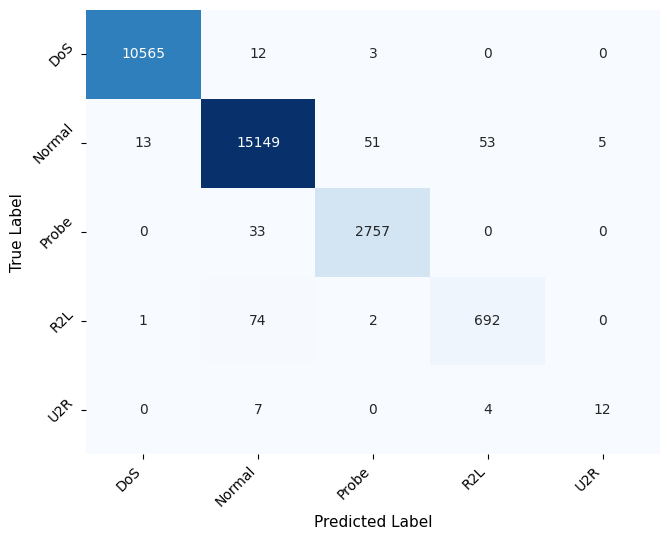

Completed LSTM seed 42: validation macro F1=0.937332; test macro F1=0.897270
Saved run results to: /kaggle/working/NSL_KDD_Full_FA_LSTM_5_seed_V2/LSTM_Seed_1

LSTM: final run 2/5; seed=43
Epoch 1/100


2026-09-28 22:01:17.734329: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1626/1630 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9257 - loss: 0.3232

2026-09-28 22:01:29.335177: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1630/1630 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.9577 - loss: 0.1540 - val_accuracy: 0.9775 - val_loss: 0.0705
Epoch 2/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9794 - loss: 0.0656 - val_accuracy: 0.9829 - val_loss: 0.0582
Epoch 3/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9828 - loss: 0.0565 - val_accuracy: 0.9864 - val_loss: 0.0516
Epoch 4/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9847 - loss: 0.0508 - val_accuracy: 0.9875 - val_loss: 0.0482
Epoch 5/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9858 - loss: 0.0474 - val_accuracy: 0.9880 - val_loss: 0.0465
Epoch 6/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9875 - loss: 0.0435 - val_accuracy: 0.9885 - val_loss: 0.0446
Epoch 7/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9878 - loss: 0.0425 - val_accuracy: 0.9889 - val_loss: 0.0436
Epoch 8/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9882 - loss: 0.0420 - val

2026-09-28 22:07:14.442662: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-28 22:07:20.471591: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

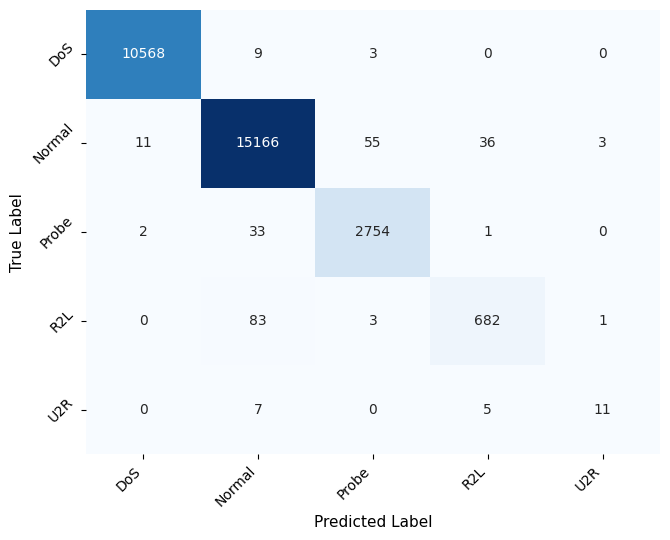

Completed LSTM seed 43: validation macro F1=0.918227; test macro F1=0.893261
Saved run results to: /kaggle/working/NSL_KDD_Full_FA_LSTM_5_seed_V2/LSTM_Seed_2

LSTM: final run 3/5; seed=44
Epoch 1/100


2026-09-28 22:07:32.189003: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1630/1630 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9210 - loss: 0.3240

2026-09-28 22:07:43.394914: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1630/1630 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.9564 - loss: 0.1550 - val_accuracy: 0.9785 - val_loss: 0.0714
Epoch 2/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9791 - loss: 0.0665 - val_accuracy: 0.9799 - val_loss: 0.0602
Epoch 3/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9825 - loss: 0.0563 - val_accuracy: 0.9855 - val_loss: 0.0514
Epoch 4/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9849 - loss: 0.0502 - val_accuracy: 0.9873 - val_loss: 0.0475
Epoch 5/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9863 - loss: 0.0465 - val_accuracy: 0.9870 - val_loss: 0.0461
Epoch 6/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9873 - loss: 0.0436 - val_accuracy: 0.9878 - val_loss: 0.0449
Epoch 7/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9877 - loss: 0.0427 - val_accuracy: 0.9879 - val_loss: 0.0445
Epoch 8/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9883 - loss: 0.0405 - val

2026-09-28 22:14:17.948436: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-28 22:14:23.977417: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

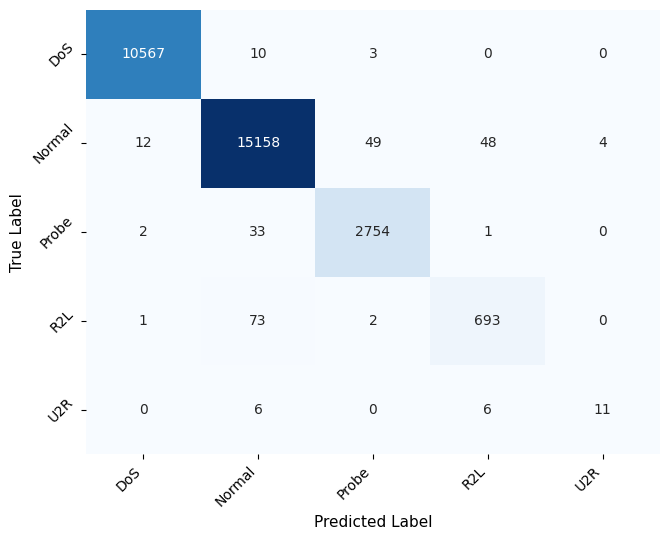

Completed LSTM seed 44: validation macro F1=0.938398; test macro F1=0.893500
Saved run results to: /kaggle/working/NSL_KDD_Full_FA_LSTM_5_seed_V2/LSTM_Seed_3

LSTM: final run 4/5; seed=45
Epoch 1/100


2026-09-28 22:14:35.359436: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1624/1630 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9221 - loss: 0.3261

2026-09-28 22:14:46.495409: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1630/1630 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.9571 - loss: 0.1563 - val_accuracy: 0.9783 - val_loss: 0.0734
Epoch 2/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9792 - loss: 0.0668 - val_accuracy: 0.9819 - val_loss: 0.0600
Epoch 3/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9831 - loss: 0.0555 - val_accuracy: 0.9835 - val_loss: 0.0540
Epoch 4/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9850 - loss: 0.0495 - val_accuracy: 0.9855 - val_loss: 0.0501
Epoch 5/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9867 - loss: 0.0457 - val_accuracy: 0.9864 - val_loss: 0.0463
Epoch 6/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9876 - loss: 0.0435 - val_accuracy: 0.9870 - val_loss: 0.0442
Epoch 7/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9884 - loss: 0.0413 - val_accuracy: 0.9874 - val_loss: 0.0442
Epoch 8/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9885 - loss: 0.0401 - va

2026-09-28 22:21:13.581311: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-28 22:21:19.870751: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

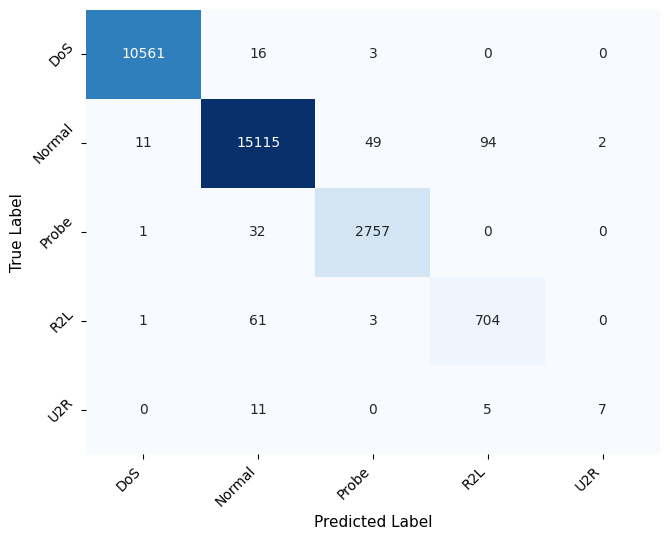

Completed LSTM seed 45: validation macro F1=0.915477; test macro F1=0.861381
Saved run results to: /kaggle/working/NSL_KDD_Full_FA_LSTM_5_seed_V2/LSTM_Seed_4

LSTM: final run 5/5; seed=46
Epoch 1/100


2026-09-28 22:21:32.110683: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1621/1630 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9245 - loss: 0.3247

2026-09-28 22:21:43.591869: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


1630/1630 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - accuracy: 0.9579 - loss: 0.1542 - val_accuracy: 0.9789 - val_loss: 0.0692
Epoch 2/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9792 - loss: 0.0651 - val_accuracy: 0.9832 - val_loss: 0.0563
Epoch 3/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9831 - loss: 0.0543 - val_accuracy: 0.9866 - val_loss: 0.0497
Epoch 4/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9849 - loss: 0.0493 - val_accuracy: 0.9876 - val_loss: 0.0461
Epoch 5/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9864 - loss: 0.0460 - val_accuracy: 0.9890 - val_loss: 0.0435
Epoch 6/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9876 - loss: 0.0436 - val_accuracy: 0.9894 - val_loss: 0.0418
Epoch 7/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9881 - loss: 0.0413 - val_accuracy: 0.9893 - val_loss: 0.0412
Epoch 8/100
1630/1630 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9884 - loss: 0.0406 - val

2026-09-28 22:29:27.535216: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-28 22:29:33.630545: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

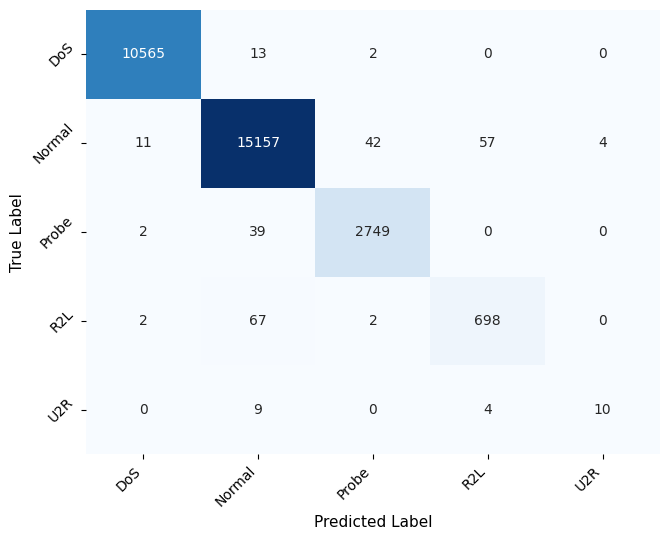

Completed LSTM seed 46: validation macro F1=0.942804; test macro F1=0.885848
Saved run results to: /kaggle/working/NSL_KDD_Full_FA_LSTM_5_seed_V2/LSTM_Seed_5


,Model,Run,Seed,Training_Time_s,Validation_F1_macro,Test_Loss,Accuracy,Precision_macro,Recall_macro,F1_macro,...,Recall_weighted,F1_weighted,MCC,ROC_AUC_macro_OvR,FPR_macro,FPR_micro_overall,FPR_weighted,Inference_Time_s,Latency_ms_per_sample,Throughput_samples_per_s
0,LSTM,1,42,362.759659,0.937332,0.036877,0.991234,0.920060,0.880075,0.897270,...,0.991234,0.991170,0.985189,0.997960,0.002780,0.002191,0.005134,2.029635,0.068958,14501.618725
1,LSTM,2,43,356.772272,0.918227,0.036303,0.991438,0.928759,0.868843,0.893261,...,0.991438,0.991326,0.985526,0.997500,0.002780,0.002140,0.005339,1.963819,0.066722,14987.635502
2,LSTM,3,44,405.819613,0.938398,0.036458,0.991506,0.926234,0.871580,0.893500,...,0.991506,0.991424,0.985646,0.997325,0.002698,0.002123,0.004998,1.903824,0.064683,15459.935357
3,LSTM,4,45,398.259799,0.915477,0.039218,0.990181,0.925165,0.839197,0.861381,...,0.990181,0.990108,0.983432,0.998216,0.002950,0.002455,0.004930,2.041578,0.069364,14416.787819
4,LSTM,5,46,475.489358,0.942804,0.036329,0.991370,0.921533,0.863775,0.885848,...,0.991370,0.991289,0.985415,0.998103,0.002765,0.002157,0.005195,1.921910,0.065298,15314.454437


In [21]:
def run_five_seed_experiment(
    model_name,
    model_builder,
    parameters,
    X_train_input,
    X_val_input,
    X_test_input,
    batch_size_key,
):
    """Train, evaluate, time, and save the LSTM model for five seeds."""

    labels = np.arange(
        number_of_classes
    )

    run_rows = []
    per_class_rows = []
    representative_candidates = []

    for run_number, seed in enumerate(
        RUN_SEEDS,
        start=1,
    ):
        print(
            "\n" + "=" * 72
        )
        print(
            f"{model_name}: final run "
            f"{run_number}/{N_FINAL_RUNS}; "
            f"seed={seed}"
        )
        print(
            "=" * 72
        )

        # ----------------------------------------------------
        # Separate output folder for this independent run.
        # LSTM_Seed_1 ... LSTM_Seed_5
        # ----------------------------------------------------
        seed_output_directory = (
            MODEL_OUTPUT_DIRECTORY
            / f"LSTM_Seed_{run_number}"
        )

        seed_output_directory.mkdir(
            parents=True,
            exist_ok=True,
        )

        tf.keras.backend.clear_session()
        set_final_run_seed(seed)

        model = model_builder(
            parameters
        )

        # ----------------------------------------------------
        # Training
        # ----------------------------------------------------
        training_start = (
            time.perf_counter()
        )

        early_stopping = (
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=EARLY_STOPPING_PATIENCE,
                restore_best_weights=True,
            )
        )

        history = model.fit(
            X_train_input,
            y_train,
            epochs=MAX_EPOCHS_LSTM,
            batch_size=parameters[
                batch_size_key
            ],
            validation_data=(
                X_val_input,
                y_val,
            ),
            callbacks=[
                early_stopping
            ],
            shuffle=True,
            verbose=1,
        )

        training_time = (
            time.perf_counter()
            - training_start
        )

        # ----------------------------------------------------
        # Validation macro F1
        # ----------------------------------------------------
        validation_probabilities = (
            model.predict(
                X_val_input,
                verbose=0,
            )
        )

        validation_predictions = (
            np.argmax(
                validation_probabilities,
                axis=1,
            )
        )

        validation_macro_f1 = f1_score(
            y_val,
            validation_predictions,
            labels=labels,
            average="macro",
            zero_division=0,
        )

        # ----------------------------------------------------
        # Test evaluation and timing
        # ----------------------------------------------------
        evaluation = model.evaluate(
            X_test_input,
            y_test,
            verbose=0,
            return_dict=True,
        )

        (
            test_probabilities,
            timing_metrics,
            timing_repetitions,
        ) = benchmark_full_test_prediction(
            model,
            X_test_input,
        )

        pd.DataFrame(
            {
                "Repetition": np.arange(
                    1,
                    len(timing_repetitions) + 1,
                ),
                "Inference_Time_s": timing_repetitions,
                "Latency_ms_per_sample": [
                    value / len(X_test_input) * 1000.0
                    for value in timing_repetitions
                ],
            }
        ).to_csv(
            seed_output_directory
            / "inference_timing_repetitions.csv",
            index=False,
        )

        test_predictions = np.argmax(
            test_probabilities,
            axis=1,
        )

        test_metrics = calculate_test_metrics(
            y_test,
            test_predictions,
            test_probabilities,
            labels,
        )

        # ----------------------------------------------------
        # Scalar metrics
        # ----------------------------------------------------
        run_row = {
            "Model": model_name,
            "Run": run_number,
            "Seed": seed,
            "Training_Time_s": float(
                training_time
            ),
            "Validation_F1_macro": float(
                validation_macro_f1
            ),
            "Test_Loss": float(
                evaluation["loss"]
            ),
            **test_metrics,
            **timing_metrics,
        }

        run_rows.append(
            run_row
        )

        pd.DataFrame(
            [run_row]
        ).to_csv(
            seed_output_directory
            / "scalar_metrics.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Readable macro-only metrics.
        # ----------------------------------------------------
        macro_metrics_row = {
            "Model": run_row["Model"],
            "Run": run_row["Run"],
            "Seed": run_row["Seed"],
            "Precision_macro": run_row["Precision_macro"],
            "Recall_macro": run_row["Recall_macro"],
            "F1_macro": run_row["F1_macro"],
            "ROC_AUC_macro_OvR": run_row["ROC_AUC_macro_OvR"],
            "FPR_macro": run_row["FPR_macro"],
        }

        pd.DataFrame(
            [macro_metrics_row]
        ).to_csv(
            seed_output_directory
            / "macro_metrics.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Readable weighted-average metrics.
        # ----------------------------------------------------
        weighted_metrics_row = {
            "Model": run_row["Model"],
            "Run": run_row["Run"],
            "Seed": run_row["Seed"],
            "Precision_weighted": run_row["Precision_weighted"],
            "Recall_weighted": run_row["Recall_weighted"],
            "F1_weighted": run_row["F1_weighted"],
            "FPR_weighted": run_row["FPR_weighted"],
        }

        pd.DataFrame(
            [weighted_metrics_row]
        ).to_csv(
            seed_output_directory
            / "weighted_average_metrics.csv",
            index=False,
        )


        # ----------------------------------------------------
        # Full classification report
        # ----------------------------------------------------
        seed_classification_report = (
            classification_report(
                y_test,
                test_predictions,
                labels=labels,
                target_names=(
                    label_encoder.classes_
                ),
                output_dict=True,
                zero_division=0,
            )
        )

        pd.DataFrame(
            seed_classification_report
        ).transpose().to_csv(
            seed_output_directory
            / "classification_report.csv"
        )

        # ----------------------------------------------------
        # Per-class Precision / Recall / F1 / FPR
        # ----------------------------------------------------
        (
            precision_values,
            recall_values,
            f1_values,
            support_values,
        ) = precision_recall_fscore_support(
            y_test,
            test_predictions,
            labels=labels,
            zero_division=0,
        )

        class_confusion_matrices = (
            multilabel_confusion_matrix(
                y_test,
                test_predictions,
                labels=labels,
            )
        )

        seed_per_class_rows = []

        for (
            class_index,
            class_name,
        ) in enumerate(
            label_encoder.classes_
        ):
            (
                true_negative,
                false_positive,
                false_negative,
                true_positive,
            ) = class_confusion_matrices[
                class_index
            ].ravel()

            fpr_denominator = (
                false_positive
                + true_negative
            )

            class_fpr = (
                false_positive
                / fpr_denominator
                if fpr_denominator
                else 0.0
            )

            per_class_row = {
                "Model": model_name,
                "Run": run_number,
                "Seed": seed,
                "Class": class_name,
                "Precision": float(
                    precision_values[
                        class_index
                    ]
                ),
                "Recall": float(
                    recall_values[
                        class_index
                    ]
                ),
                "F1": float(
                    f1_values[
                        class_index
                    ]
                ),
                "FPR": float(
                    class_fpr
                ),
                "TP": int(
                    true_positive
                ),
                "TN": int(
                    true_negative
                ),
                "FP": int(
                    false_positive
                ),
                "FN": int(
                    false_negative
                ),
                "Support": int(
                    support_values[
                        class_index
                    ]
                ),
            }

            seed_per_class_rows.append(
                per_class_row
            )

            per_class_rows.append(
                per_class_row
            )

        pd.DataFrame(
            seed_per_class_rows
        ).to_csv(
            seed_output_directory
            / "per_class_metrics_and_fpr.csv",
            index=False,
        )

        # ----------------------------------------------------
        # FPR summary for this seed
        # ----------------------------------------------------
        pd.DataFrame(
            [
                {
                    "Model": model_name,
                    "Run": run_number,
                    "Seed": seed,
                    "FPR_macro": (
                        test_metrics[
                            "FPR_macro"
                        ]
                    ),
                    "FPR_micro_overall": (
                        test_metrics[
                            "FPR_micro_overall"
                        ]
                    ),
                    "FPR_weighted": (
                        test_metrics[
                            "FPR_weighted"
                        ]
                    ),
                }
            ]
        ).to_csv(
            seed_output_directory
            / "false_positive_rate_summary.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Confusion matrix: CSV + PDF + PNG
        # ----------------------------------------------------
        seed_confusion_matrix = (
            confusion_matrix(
                y_test,
                test_predictions,
                labels=labels,
            )
        )

        seed_confusion_matrix_df = (
            pd.DataFrame(
                seed_confusion_matrix,
                index=(
                    label_encoder.classes_
                ),
                columns=(
                    label_encoder.classes_
                ),
            )
        )

        seed_confusion_matrix_df.index.name = (
            "True_Label"
        )
        seed_confusion_matrix_df.columns.name = (
            "Predicted_Label"
        )

        seed_confusion_matrix_df.to_csv(
            seed_output_directory
            / "confusion_matrix.csv"
        )

        plot_publication_confusion_matrix(
            y_test,
            test_predictions,
            seed_output_directory
            / "confusion_matrix",
        )

        # ----------------------------------------------------
        # Training history
        # ----------------------------------------------------
        history_df = pd.DataFrame(
            history.history
        )

        history_df.index = (
            np.arange(
                1,
                len(history_df) + 1,
            )
        )
        history_df.index.name = (
            "Epoch"
        )

        history_df.to_csv(
            seed_output_directory
            / "training_history.csv"
        )

        # ----------------------------------------------------
        # Test predictions and probabilities
        # ----------------------------------------------------
        predictions_df = pd.DataFrame(
            {
                "True_Label_Encoded": (
                    y_test
                ),
                "Predicted_Label_Encoded": (
                    test_predictions
                ),
                "True_Label": (
                    label_encoder.inverse_transform(
                        y_test
                    )
                ),
                "Predicted_Label": (
                    label_encoder.inverse_transform(
                        test_predictions
                    )
                ),
            }
        )

        for (
            class_index,
            class_name,
        ) in enumerate(
            label_encoder.classes_
        ):
            predictions_df[
                f"Probability_{class_name}"
            ] = test_probabilities[
                :,
                class_index,
            ]

        predictions_df.to_csv(
            seed_output_directory
            / "test_predictions_and_probabilities.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Save trained model
        # ----------------------------------------------------
        model_path = (
            seed_output_directory
            / f"{model_name.lower()}_seed_{seed}.keras"
        )

        model.save(
            model_path
        )

        # ----------------------------------------------------
        # Save run metadata and exact pre-stored parameters
        # ----------------------------------------------------
        run_metadata = {
            "Model": model_name,
            "Run": run_number,
            "Seed": seed,
            "N_Final_Runs": N_FINAL_RUNS,
            "Training_Samples": int(
                len(X_train_input)
            ),
            "Validation_Samples": int(
                len(X_val_input)
            ),
            "Test_Samples": int(
                len(X_test_input)
            ),
            "Hyperparameters": parameters,
            "Ablation_Mode": ABLATION_MODE,
            "Kept_Anomaly_Features": kept_anomaly_features,
            "Dropped_Anomaly_Features": features_to_drop,
            "Max_Epochs": MAX_EPOCHS_LSTM,
            "Early_Stopping_Patience": EARLY_STOPPING_PATIENCE,
            "Warmup_Runs": N_WARMUP_RUNS,
            "Timed_Inference_Repetitions": N_BENCHMARK_RUNS,
        }

        with open(
            seed_output_directory
            / "run_metadata.json",
            "w",
            encoding="utf-8",
        ) as json_file:
            json.dump(
                run_metadata,
                json_file,
                indent=2,
            )

        representative_candidates.append(
            {
                "Seed": seed,
                "Run": run_number,
                "F1_macro": (
                    test_metrics[
                        "F1_macro"
                    ]
                ),
                "Predictions": (
                    test_predictions.copy()
                ),
            }
        )

        print(
            f"Completed {model_name} seed {seed}: "
            f"validation macro F1={validation_macro_f1:.6f}; "
            f"test macro F1={test_metrics['F1_macro']:.6f}"
        )

        print(
            "Saved run results to:",
            seed_output_directory.resolve(),
        )

        del history
        del model
        gc.collect()
        tf.keras.backend.clear_session()

    return (
        pd.DataFrame(
            run_rows
        ),
        pd.DataFrame(
            per_class_rows
        ),
        representative_candidates,
    )


# ============================================================
# LSTM-only experiment definition
# Keep the original experiment-definition variable name.
# ============================================================
experiment_definitions = [
    {
        "model_name": "LSTM",
        "model_builder": build_final_lstm,
        "parameters": best_params_lstm_03,
        "X_train_input": X_train_reshaped_lstm,
        "X_val_input": X_val_reshaped_lstm,
        "X_test_input": X_test_reshaped_lstm,
        "batch_size_key": "batch_size_lstm",
    },
]


run_result_frames = []
per_class_result_frames = []
representative_candidates_by_model = {}


for experiment in experiment_definitions:
    (
        run_frame,
        class_frame,
        candidates,
    ) = run_five_seed_experiment(
        **experiment
    )

    run_result_frames.append(
        run_frame
    )
    per_class_result_frames.append(
        class_frame
    )

    representative_candidates_by_model[
        experiment["model_name"]
    ] = candidates


# Keep the original result-variable names.
all_run_results = pd.concat(
    run_result_frames,
    ignore_index=True,
)

all_per_class_results = pd.concat(
    per_class_result_frames,
    ignore_index=True,
)


all_run_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_5_seed_run_results.csv",
    index=False,
)

all_per_class_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_per_class_5_seed_run_results.csv",
    index=False,
)




# ============================================================
# Separate five-seed macro and weighted-average result tables.
# ============================================================
macro_metric_columns = [
    "Model",
    "Run",
    "Seed",
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "ROC_AUC_macro_OvR",
    "FPR_macro",
]

weighted_metric_columns = [
    "Model",
    "Run",
    "Seed",
    "Precision_weighted",
    "Recall_weighted",
    "F1_weighted",
    "FPR_weighted",
]

macro_metrics_5_seed_results = (
    all_run_results[
        macro_metric_columns
    ].copy()
)

weighted_average_metrics_5_seed_results = (
    all_run_results[
        weighted_metric_columns
    ].copy()
)

macro_metrics_5_seed_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_macro_metrics_5_seed_results.csv",
    index=False,
)

weighted_average_metrics_5_seed_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_weighted_average_metrics_5_seed_results.csv",
    index=False,
)

display(
    all_run_results
)


### Mean ± sample standard deviation across the five LSTM seeds


In [22]:
identifier_columns = {
    "Model",
    "Run",
    "Seed",
}

metric_columns = [
    column
    for column in all_run_results.columns
    if column not in identifier_columns
]

summary_records = []


for (
    model_name,
    model_rows,
) in all_run_results.groupby(
    "Model",
    sort=False,
):
    for metric_name in metric_columns:
        metric_values = (
            model_rows[
                metric_name
            ].astype(float)
        )

        metric_mean = float(
            metric_values.mean()
        )

        metric_sd = float(
            metric_values.std(
                ddof=1
            )
        )

        summary_records.append(
            {
                "Model": model_name,
                "Metric": metric_name,
                "Mean": metric_mean,
                "SD": metric_sd,
                "N": int(
                    metric_values
                    .notna()
                    .sum()
                ),
                "Mean ± SD": format_mean_sd(
                    metric_mean,
                    metric_sd,
                ),
            }
        )


five_run_summary_long = pd.DataFrame(
    summary_records
)

five_run_summary_table = (
    five_run_summary_long.pivot(
        index="Model",
        columns="Metric",
        values="Mean ± SD",
    )
    .reindex(["LSTM"])
)


# Backward-compatible aliases for downstream code that used the
# original five-run variable names.
five_run_summary_long = (
    five_run_summary_long
)
five_run_summary_table = (
    five_run_summary_table
)


five_run_summary_long.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "five_run_mean_sd_long.csv",
    index=False,
)

five_run_summary_table.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "five_run_mean_sd_report_table.csv"
)




# ============================================================
# Separate mean ± SD tables for macro and weighted metrics.
# ============================================================
macro_summary_metric_names = [
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "ROC_AUC_macro_OvR",
    "FPR_macro",
]

weighted_summary_metric_names = [
    "Precision_weighted",
    "Recall_weighted",
    "F1_weighted",
    "FPR_weighted",
]

macro_metrics_mean_sd = (
    five_run_summary_long[
        five_run_summary_long[
            "Metric"
        ].isin(
            macro_summary_metric_names
        )
    ][
        [
            "Model",
            "Metric",
            "Mean",
            "SD",
            "N",
            "Mean ± SD",
        ]
    ].reset_index(
        drop=True
    )
)

weighted_average_metrics_mean_sd = (
    five_run_summary_long[
        five_run_summary_long[
            "Metric"
        ].isin(
            weighted_summary_metric_names
        )
    ][
        [
            "Model",
            "Metric",
            "Mean",
            "SD",
            "N",
            "Mean ± SD",
        ]
    ].reset_index(
        drop=True
    )
)

macro_metrics_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "macro_metrics_5_seed_mean_sd.csv",
    index=False,
)

weighted_average_metrics_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "weighted_average_metrics_5_seed_mean_sd.csv",
    index=False,
)

print(
    "Macro metrics — 5-run mean ± sample SD:"
)
display(
    macro_metrics_mean_sd
)

print(
    "Weighted-average metrics — 5-run mean ± sample SD:"
)
display(
    weighted_average_metrics_mean_sd
)

print(
    "Five-run LSTM journal report "
    "(mean ± sample SD; n = 5):"
)

display(
    five_run_summary_table
)


Macro metrics — 5-run mean ± sample SD:


,Model,Metric,Mean,SD,N,Mean ± SD
0,LSTM,Precision_macro,0.924350,0.003535,5,0.924350 ± 0.003535
1,LSTM,Recall_macro,0.864694,0.015429,5,0.864694 ± 0.015429
2,LSTM,F1_macro,0.886252,0.014507,5,0.886252 ± 0.014507
3,LSTM,ROC_AUC_macro_OvR,0.997821,0.000389,5,0.997821 ± 0.000389
4,LSTM,FPR_macro,0.002795,0.000093,5,0.002795 ± 0.000093


Weighted-average metrics — 5-run mean ± sample SD:


,Model,Metric,Mean,SD,N,Mean ± SD
0,LSTM,Precision_weighted,0.991065,0.000480,5,0.991065 ± 0.000480
1,LSTM,Recall_weighted,0.991146,0.000549,5,0.991146 ± 0.000549
2,LSTM,F1_weighted,0.991063,0.000542,5,0.991063 ± 0.000542
3,LSTM,FPR_weighted,0.005119,0.000162,5,0.005119 ± 0.000162


Five-run LSTM journal report (mean ± sample SD; n = 5):


Metric,Accuracy,F1_macro,F1_weighted,FPR_macro,FPR_micro_overall,FPR_weighted,Inference_Time_s,Latency_ms_per_sample,MCC,Precision_macro,Precision_weighted,ROC_AUC_macro_OvR,Recall_macro,Recall_weighted,Test_Loss,Throughput_samples_per_s,Training_Time_s,Validation_F1_macro
Model,,,,,,,,,,,,,,,,,,
LSTM,0.991146 ± 0.000549,0.886252 ± 0.014507,0.991063 ± 0.000542,0.002795 ± 0.000093,0.002214 ± 0.000137,0.005119 ± 0.000162,1.972153 ± 0.062022,0.067005 ± 0.002107,0.985042 ± 0.000915,0.924350 ± 0.003535,0.991065 ± 0.000480,0.997821 ± 0.000389,0.864694 ± 0.015429,0.991146 ± 0.000549,0.037037 ± 0.001241,14936.086368 ± 468.687153,399.820140 ± 47.410065,0.930448 ± 0.012617


### Per-class mean ± sample standard deviation

In [23]:
per_class_summary_records = []


for (
    model_name,
    class_name,
), class_rows in (
    all_per_class_results.groupby(
        ["Model", "Class"],
        sort=False,
    )
):
    record = {
        "Model": model_name,
        "Class": class_name,
        "Support": int(
            class_rows[
                "Support"
            ].iloc[0]
        ),
        "N": int(
            len(class_rows)
        ),
    }

    for metric_name in [
        "Precision",
        "Recall",
        "F1",
        "FPR",
    ]:
        metric_mean = float(
            class_rows[
                metric_name
            ].mean()
        )

        metric_sd = float(
            class_rows[
                metric_name
            ].std(ddof=1)
        )

        record[
            f"{metric_name}_Mean"
        ] = metric_mean

        record[
            f"{metric_name}_SD"
        ] = metric_sd

        record[
            f"{metric_name}_Mean ± SD"
        ] = format_mean_sd(
            metric_mean,
            metric_sd,
        )

    per_class_summary_records.append(
        record
    )


# Keep the original summary variable name.
per_class_mean_sd = pd.DataFrame(
    per_class_summary_records
)


per_class_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "per_class_five_run_mean_sd.csv",
    index=False,
)


display(
    per_class_mean_sd
)


,Model,Class,Support,N,Precision_Mean,Precision_SD,Precision_Mean ± SD,Recall_Mean,Recall_SD,Recall_Mean ± SD,F1_Mean,F1_SD,F1_Mean ± SD,FPR_Mean,FPR_SD,FPR_Mean ± SD
0,LSTM,DoS,10580,5,0.998677,0.000094,0.998677 ± 0.000094,0.998601,0.000254,0.998601 ± 0.000254,0.998639,0.000122,0.998639 ± 0.000122,0.000743,0.000053,0.000743 ± 0.000053
1,LSTM,Normal,15271,5,0.991778,0.000302,0.991778 ± 0.000302,0.992011,0.001306,0.992011 ± 0.001306,0.991894,0.000552,0.991894 ± 0.000552,0.008869,0.000337,0.008869 ± 0.000337
2,LSTM,Probe,2790,5,0.980635,0.001878,0.980635 ± 0.001878,0.987168,0.001172,0.987168 ± 0.001172,0.983889,0.000694,0.983889 ± 0.000694,0.002042,0.000203,0.002042 ± 0.000203
3,LSTM,R2L,769,5,0.917740,0.024439,0.917740 ± 0.024439,0.902211,0.010580,0.902211 ± 0.010580,0.909651,0.007856,0.909651 ± 0.007856,0.002191,0.000748,0.002191 ± 0.000748
4,LSTM,U2R,23,5,0.732923,0.027798,0.732923 ± 0.027798,0.443478,0.083632,0.443478 ± 0.083632,0.547187,0.064966,0.547187 ± 0.064966,0.000129,0.000037,0.000129 ± 0.000037


### Representative LSTM confusion matrix

The representative run is the seed whose test macro F1 is closest to the
5-run LSTM mean.

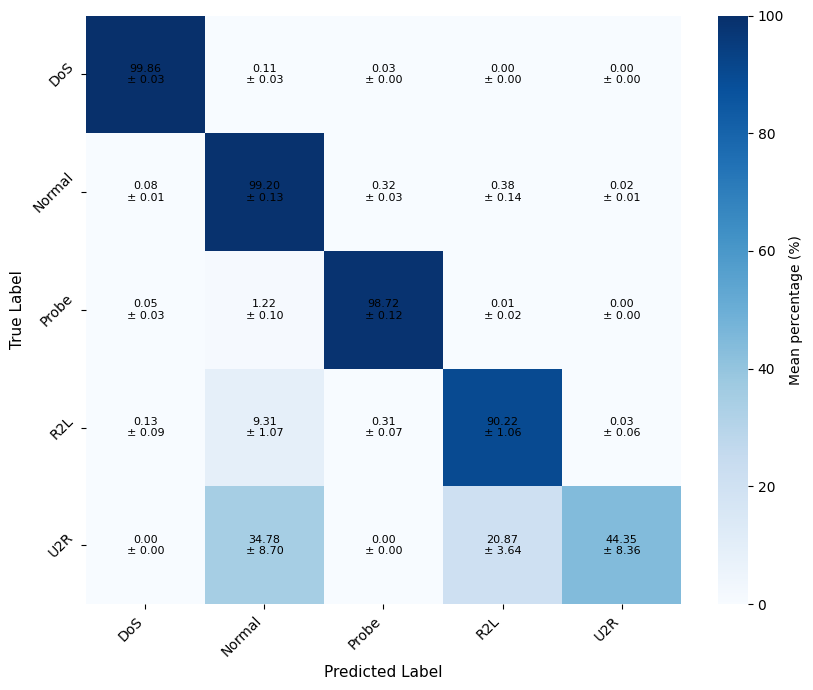

Saved NSL-KDD LSTM five-seed normalized confusion matrix mean ± sample SD.


In [24]:
# ============================================================
# Five-seed normalized confusion matrix: mean ± sample SD
# ============================================================

# One final row-normalized matrix is plotted. Seed-specific
# normalized matrices are used internally only to calculate
# cell-wise mean and sample standard deviation.

labels = np.arange(
    number_of_classes
)

class_names = (
    label_encoder.classes_
)

normalized_confusion_matrices = []

for candidate in (
    representative_candidates_by_model[
        "LSTM"
    ]
):

    seed_predictions = (
        candidate[
            "Predictions"
        ]
    )

    seed_cm = confusion_matrix(
        y_test,
        seed_predictions,
        labels=labels,
    )

    row_totals = seed_cm.sum(
        axis=1,
        keepdims=True,
    )

    seed_cm_normalized = np.divide(
        seed_cm,
        row_totals,
        out=np.zeros_like(
            seed_cm,
            dtype=float,
        ),
        where=row_totals != 0,
    )

    normalized_confusion_matrices.append(
        seed_cm_normalized
    )

normalized_confusion_matrices = np.stack(
    normalized_confusion_matrices,
    axis=0,
)

if normalized_confusion_matrices.shape[0] != len(RUN_SEEDS):
    raise ValueError(
        "The number of normalized confusion matrices does not "
        "match the five final-run seeds."
    )

mean_cm = np.mean(
    normalized_confusion_matrices,
    axis=0,
)

sd_cm = np.std(
    normalized_confusion_matrices,
    axis=0,
    ddof=1,
)

mean_cm_pct = mean_cm * 100.0
sd_cm_pct = sd_cm * 100.0

mean_cm_df = pd.DataFrame(
    mean_cm_pct,
    index=class_names,
    columns=class_names,
)

sd_cm_df = pd.DataFrame(
    sd_cm_pct,
    index=class_names,
    columns=class_names,
)

mean_cm_df.index.name = "True_Label"
mean_cm_df.columns.name = "Predicted_Label"

sd_cm_df.index.name = "True_Label"
sd_cm_df.columns.name = "Predicted_Label"

mean_cm_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_normalized_confusion_matrix_5_seed_mean.csv"
)

sd_cm_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_normalized_confusion_matrix_5_seed_sd.csv"
)

mean_sd_table = pd.DataFrame(
    index=class_names,
    columns=class_names,
    dtype=object,
)

for i in range(number_of_classes):
    for j in range(number_of_classes):
        mean_sd_table.iloc[i, j] = (
            f"{mean_cm_pct[i, j]:.2f} "
            f"± {sd_cm_pct[i, j]:.2f}"
        )

mean_sd_table.index.name = "True_Label"
mean_sd_table.columns.name = "Predicted_Label"

mean_sd_table.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_normalized_confusion_matrix_5_seed_mean_sd.csv"
)

plt.figure(
    figsize=(8.5, 7.0)
)

ax = sns.heatmap(
    mean_cm_pct,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=100,
    cbar_kws={
        "label": "Mean percentage (%)"
    },
)

for i in range(number_of_classes):
    for j in range(number_of_classes):
        ax.text(
            j + 0.5,
            i + 0.5,
            (
                f"{mean_cm_pct[i, j]:.2f}"
                f"\n± {sd_cm_pct[i, j]:.2f}"
            ),
            ha="center",
            va="center",
            fontsize=8,
        )

plt.xlabel(
    "Predicted Label",
    fontsize=11,
)

plt.ylabel(
    "True Label",
    fontsize=11,
)

plt.xticks(
    rotation=45,
    ha="right",
)

plt.yticks(
    rotation=45,
)

plt.tight_layout()

plt.savefig(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_normalized_confusion_matrix_5_seed_mean_sd.pdf",
    bbox_inches="tight",
)

plt.savefig(
    REPORT_OUTPUT_DIRECTORY
    / "lstm_normalized_confusion_matrix_5_seed_mean_sd.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()
plt.close()

print(
    "Saved NSL-KDD LSTM five-seed normalized confusion "
    "matrix mean ± sample SD."
)


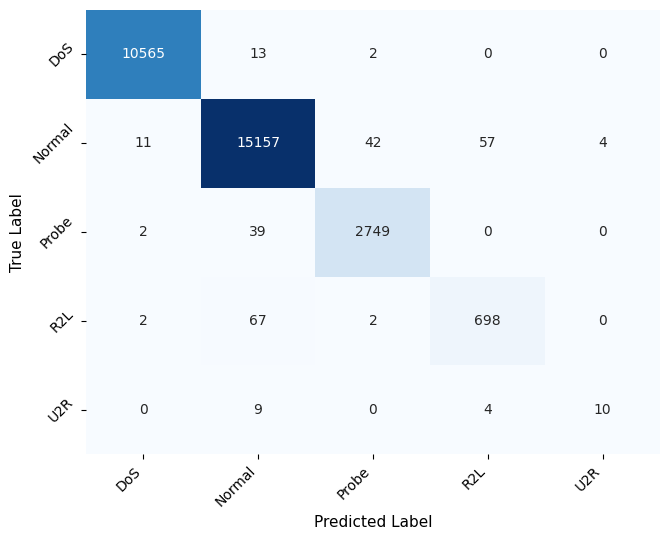

,Model,Representative_Run,Representative_Seed,Representative_F1_macro,Five_Run_Mean_F1_macro
0,LSTM,5,46,0.885848,0.886252


All five-run LSTM outputs were saved to:


In [25]:
representative_run_records = []


for model_name in ["LSTM"]:
    candidates = (
        representative_candidates_by_model[
            model_name
        ]
    )

    model_mean_f1 = float(
        all_run_results.loc[
            all_run_results[
                "Model"
            ] == model_name,
            "F1_macro",
        ].mean()
    )

    representative = min(
        candidates,
        key=lambda item: abs(
            item["F1_macro"]
            - model_mean_f1
        ),
    )

    representative_run_records.append(
        {
            "Model": model_name,
            "Representative_Run": (
                representative["Run"]
            ),
            "Representative_Seed": (
                representative["Seed"]
            ),
            "Representative_F1_macro": (
                representative[
                    "F1_macro"
                ]
            ),
            "Five_Run_Mean_F1_macro": (
                model_mean_f1
            ),
        }
    )

    output_stem = (
        REPORT_OUTPUT_DIRECTORY
        / (
            f"{model_name.lower()}_"
            "representative_confusion_matrix"
        )
    )

    plot_publication_confusion_matrix(
        y_test,
        representative[
            "Predictions"
        ],
        output_stem,
    )

    representative_report = (
        classification_report(
            y_test,
            representative[
                "Predictions"
            ],
            labels=np.arange(
                number_of_classes
            ),
            target_names=(
                label_encoder.classes_
            ),
            output_dict=True,
            zero_division=0,
        )
    )

    pd.DataFrame(
        representative_report
    ).transpose().to_csv(
        REPORT_OUTPUT_DIRECTORY
        / (
            f"{model_name.lower()}_"
            "representative_classification_report.csv"
        )
    )


# Keep the original result-variable name.
representative_runs = pd.DataFrame(
    representative_run_records
)

representative_runs.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "representative_runs.csv",
    index=False,
)


display(
    representative_runs
)

print(
    "All five-run LSTM outputs were saved to:"
)


### Save Alloutputs


In [ ]:
# ============================================================
# Offline classifier-only inference timing from saved LSTM models
# ============================================================

# This cell can be rerun later without retraining.
# Timing excludes preprocessing and model loading.

OFFLINE_WARMUP_RUNS = 3
OFFLINE_TIMING_REPETITIONS = 5

offline_X_test = np.load(
    REPORT_OUTPUT_DIRECTORY
    / "X_test_model_input.npy"
)

offline_timing_rows = []
offline_seed_summary_rows = []

for run_number, seed in enumerate(
    RUN_SEEDS,
    start=1,
):

    model_path = (
        REPORT_OUTPUT_DIRECTORY
        / f"LSTM_Seed_{run_number}"
        / f"lstm_seed_{seed}.keras"
    )

    if not model_path.exists():
        raise FileNotFoundError(
            f"Saved LSTM model not found: {model_path}"
        )

    # Model loading is outside the timed region.
    offline_model = tf.keras.models.load_model(
        model_path,
        compile=False,
    )

    warmup_size = min(
        1024,
        len(offline_X_test),
    )

    for _ in range(
        OFFLINE_WARMUP_RUNS
    ):
        offline_model.predict(
            offline_X_test[:warmup_size],
            verbose=0,
        )

    seed_times = []

    for repetition in range(
        1,
        OFFLINE_TIMING_REPETITIONS + 1,
    ):

        start_time = time.perf_counter()

        offline_model.predict(
            offline_X_test,
            verbose=0,
        )

        elapsed_time = (
            time.perf_counter()
            - start_time
        )

        seed_times.append(
            elapsed_time
        )

        offline_timing_rows.append(
            {
                "Run": run_number,
                "Seed": seed,
                "Repetition": repetition,
                "Inference_Time_s": elapsed_time,
                "Latency_ms_per_sample": (
                    elapsed_time
                    / len(offline_X_test)
                    * 1000.0
                ),
                "Throughput_samples_per_s": (
                    len(offline_X_test)
                    / elapsed_time
                ),
            }
        )

    seed_mean_time = float(
        np.mean(seed_times)
    )

    offline_seed_summary_rows.append(
        {
            "Run": run_number,
            "Seed": seed,
            "Mean_Inference_Time_s": seed_mean_time,
            "SD_Inference_Time_s": float(
                np.std(
                    seed_times,
                    ddof=1,
                )
            ),
            "Mean_Latency_ms_per_sample": (
                seed_mean_time
                / len(offline_X_test)
                * 1000.0
            ),
            "Mean_Throughput_samples_per_s": (
                len(offline_X_test)
                / seed_mean_time
            ),
        }
    )

    del offline_model
    gc.collect()
    tf.keras.backend.clear_session()


offline_timing_repetitions_df = pd.DataFrame(
    offline_timing_rows
)

offline_timing_per_seed_df = pd.DataFrame(
    offline_seed_summary_rows
)

offline_timing_repetitions_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "offline_inference_timing_repetitions.csv",
    index=False,
)

offline_timing_per_seed_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "offline_inference_timing_per_seed.csv",
    index=False,
)

summary_rows = []

for metric_column, metric_name in [
    (
        "Mean_Inference_Time_s",
        "Inference_Time_s",
    ),
    (
        "Mean_Latency_ms_per_sample",
        "Latency_ms_per_sample",
    ),
    (
        "Mean_Throughput_samples_per_s",
        "Throughput_samples_per_s",
    ),
]:

    values = offline_timing_per_seed_df[
        metric_column
    ].to_numpy(
        dtype=float
    )

    summary_rows.append(
        {
            "Metric": metric_name,
            "Mean": float(
                np.mean(values)
            ),
            "SD": float(
                np.std(
                    values,
                    ddof=1,
                )
            ),
            "N_Seeds": len(
                RUN_SEEDS
            ),
        }
    )


offline_summary_df = pd.DataFrame(
    summary_rows
)

offline_summary_df[
    "Mean ± SD"
] = offline_summary_df.apply(
    lambda row: (
        f"{row['Mean']:.6f} ± "
        f"{row['SD']:.6f}"
    ),
    axis=1,
)

offline_summary_df.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "offline_inference_timing_summary.csv",
    index=False,
)

print(
    "Offline NSL-KDD LSTM inference timing completed."
)

display(
    offline_timing_per_seed_df
)

display(
    offline_summary_df
)
